# 03 — Prediction, compression and stability

**Question.** Does dimensionality reduction help prediction or model stability, and what does it reveal about the original model?

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/injury_reduction.yaml').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.injury_analysis.reduction import CFG,OUT,CACHE,inputs,read_table
from src.injury_analysis import reduction_plots as plots
from src.injury_analysis.common import conclusion
pd.set_option('display.max_columns',16)


## Identical temporal evaluation and common rows
Use the existing seven category-versus-IL-free risk sets at the 30-day horizon. Train through 2021, validate in 2022–2023 and evaluate in the previously examined 2024–2025 period, preserving the 60-day embargo and event-overlap safeguards. All variants use identical rows within category/partition; train-only imputation, scaling and PCA are refitted per category. Logistic C=1 is unchanged; numerical convergence is tightened for **all** new fits.

Compare original 62 features, workload/history, global PCA with 5/10/20 components or a training-learned 90%-variance cutoff, workload/history plus 10-PC or 90%-variance Statcast, and a role/hand-plus-missingness diagnostic. All PCA designs pass binary context and training-observed missingness flags through. Report total columns, not just PC count. A full-rank, unwhitened rotation is the numerical equivalence control; no component rescaling changes the regularization geometry.

Choose a global-PCA dimension by **validation AP only**, with smaller design as tie-break. Test comparisons remain exploratory; neither test AP nor trajectory appearance selects dimensions. Conditional pitcher-bootstrap intervals exclude retraining and dimension-selection uncertainty.

In [2]:
from src.injury_analysis.reduction_prediction import run_prediction,run_stability,event_concentration_audit
a,events,spec,matches=inputs()
performance=run_prediction(a,events,spec)
display(read_table('predictive_cohort'))
display(read_table('predictive_dimensions'))
display(read_table('full_rotation_sanity'))
display(read_table('validation_dimension_selection'))

PCA predictive comparison: Elbow / UCL; events={'train': 223, 'validation': 89, 'test': 110}


PCA predictive comparison: Shoulder; events={'train': 350, 'validation': 115, 'test': 125}


PCA predictive comparison: Forearm; events={'train': 109, 'validation': 41, 'test': 38}


PCA predictive comparison: Other arm; events={'train': 107, 'validation': 33, 'test': 38}


PCA predictive comparison: Trunk / neck; events={'train': 272, 'validation': 103, 'test': 65}


...

PCA predictive comparison: Hand / wrist; events={'train': 107, 'validation': 32, 'test': 29}


,category,partition,rows,events,positive_rows,run
0,Elbow / UCL,train,81145,223,1441,True
1,Elbow / UCL,validation,26796,89,600,True
2,Elbow / UCL,test,27665,110,708,True
3,Shoulder,train,81978,350,2274,True
4,Shoulder,validation,26932,115,736,True
5,Shoulder,test,27806,125,849,True
6,Forearm,train,80362,109,658,True
7,Forearm,validation,26478,41,282,True
8,Forearm,test,27236,38,279,True
9,Other arm,train,80373,107,669,True


,category,variant,source_features,missingness_indicators,retained_components,unrotated_columns,design_dimensions,retained_variance
0,Elbow / UCL,Original 62,62,45,0,107,107,1.000000
1,Elbow / UCL,Workload + history,22,13,0,35,35,1.000000
2,Elbow / UCL,PCA 5,62,45,5,47,52,0.364727
3,Elbow / UCL,PCA 10,62,45,10,47,57,0.543046
4,Elbow / UCL,PCA 20,62,45,20,47,67,0.763034
...,...,...,...,...,...,...,...,...
65,Hand / wrist,PCA 90%,62,45,30,47,77,0.900216
66,Hand / wrist,Full-rank PCA control,62,45,60,47,107,1.000000
67,Hand / wrist,WH + Statcast PCA 10,62,45,10,67,77,0.584447
68,Hand / wrist,WH + Statcast PCA 90%,62,45,23,67,90,0.902043


,category,partition,max_score_difference,score_correlation,ap_difference,tight_original_ap,legacy_default_tolerance_ap,legacy_max_score_difference
0,Elbow / UCL,validation,0.000006,1.0,2.098263e-08,0.028415,0.028254,0.041443
1,Elbow / UCL,test,0.000007,1.0,5.163970e-08,0.042629,0.043153,0.046500
2,Shoulder,validation,0.000023,1.0,8.754735e-08,0.044947,0.044729,0.075943
3,Shoulder,test,0.000024,1.0,1.663627e-07,0.055919,0.056502,0.078846
4,Forearm,validation,0.000003,1.0,-1.055999e-07,0.014891,0.014749,0.044996
5,Forearm,test,0.000003,1.0,2.045629e-07,0.022812,0.021464,0.034414
6,Other arm,validation,0.000035,1.0,-2.604317e-09,0.009864,0.010068,0.056111
7,Other arm,test,0.000031,1.0,-2.628672e-08,0.010099,0.010117,0.036579
8,Trunk / neck,validation,0.000007,1.0,8.117989e-08,0.035894,0.036355,0.049468
9,Trunk / neck,test,0.000003,1.0,7.479529e-08,0.027290,0.027586,0.052463


,category,selected_variant,validation_ap,basis
0,Elbow / UCL,PCA 90%,0.028498,Highest validation AP among predeclared global...
1,Shoulder,PCA 90%,0.038333,Highest validation AP among predeclared global...
2,Forearm,PCA 20,0.014326,Highest validation AP among predeclared global...
3,Other arm,PCA 10,0.012913,Highest validation AP among predeclared global...
4,Trunk / neck,PCA 90%,0.037810,Highest validation AP among predeclared global...
5,Lower body,PCA 90%,0.041447,Highest validation AP among predeclared global...
6,Hand / wrist,PCA 90%,0.010518,Highest validation AP among predeclared global...


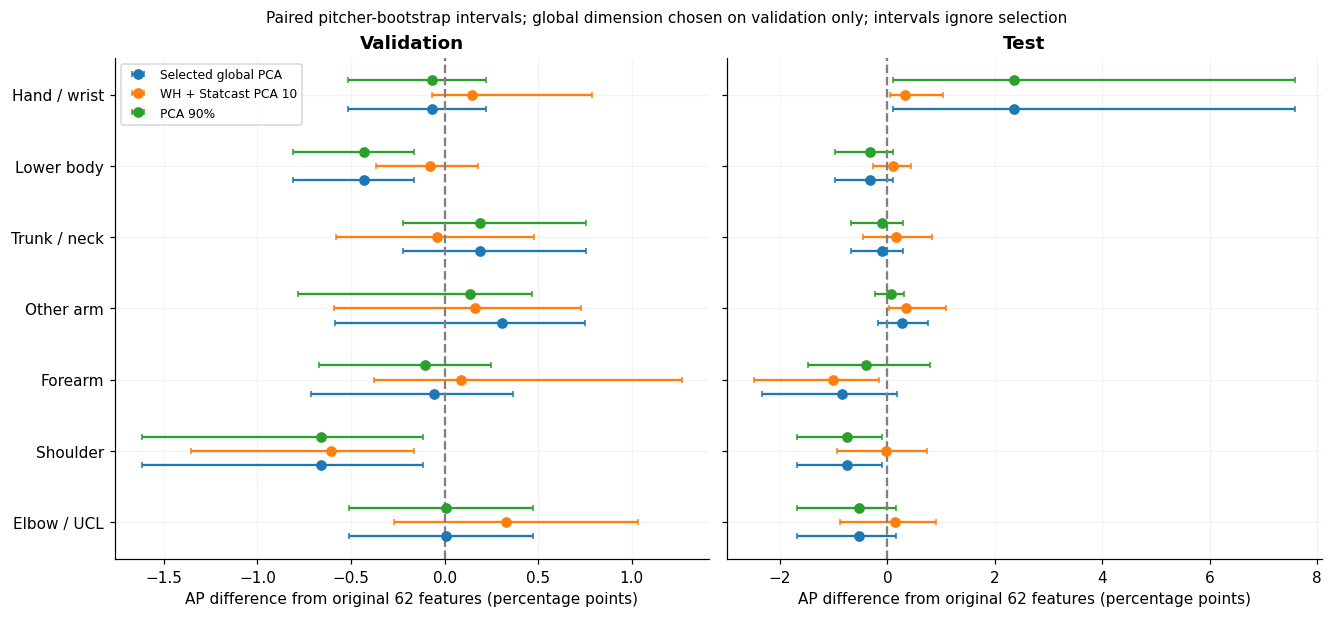

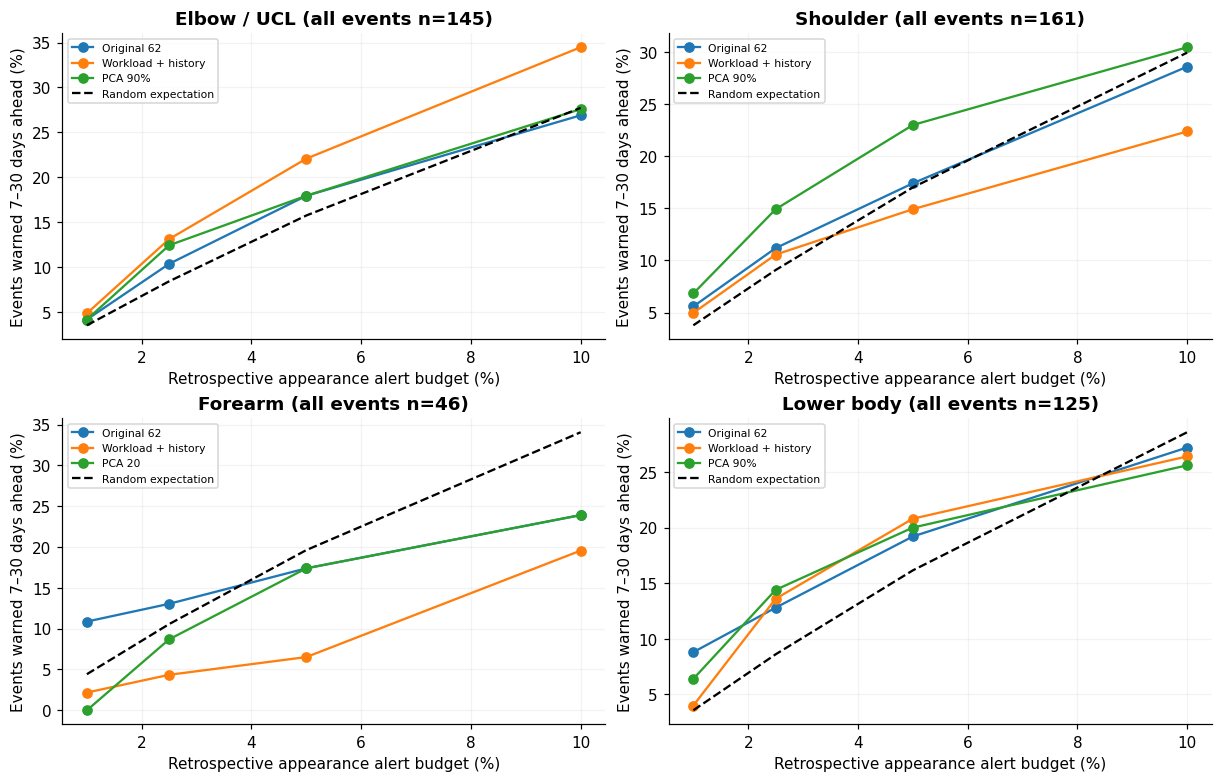

,category,variant,design_dimensions,average_precision,pr_lift,ap_delta_original,delta_low_original,delta_high_original
10,Elbow / UCL,Original 62,107,0.042629,1.665713,0.000000e+00,0.000000e+00,0.000000
11,Elbow / UCL,Workload + history,35,0.044145,1.724946,1.515895e-03,-1.185721e-02,0.013959
12,Elbow / UCL,PCA 5,52,0.033368,1.303849,-9.260773e-03,-2.492189e-02,0.000921
13,Elbow / UCL,PCA 10,57,0.033608,1.313247,-9.020266e-03,-2.381394e-02,-0.001178
14,Elbow / UCL,PCA 20,67,0.036432,1.423561,-6.197114e-03,-1.908992e-02,0.001964
...,...,...,...,...,...,...,...,...
135,Hand / wrist,PCA 90%,77,0.032748,5.165302,2.351058e-02,1.071903e-03,0.075811
136,Hand / wrist,Full-rank PCA control,107,0.009238,1.457083,1.750803e-07,-2.281085e-08,0.000001
137,Hand / wrist,WH + Statcast PCA 10,77,0.012460,1.965236,3.221909e-03,4.927605e-04,0.010386
138,Hand / wrist,WH + Statcast PCA 90%,90,0.012040,1.899065,2.802380e-03,2.887802e-05,0.009332


,category,partition,variant,reference,mean,low,high,events,pitchers
10,Elbow / UCL,test,Original 62,Original 62,0.000000,0.000000,0.000000,145,129
11,Elbow / UCL,test,Workload + history,Original 62,0.041379,-0.021437,0.119321,145,129
12,Elbow / UCL,test,PCA 5,Original 62,0.034483,-0.056389,0.128768,145,129
13,Elbow / UCL,test,PCA 10,Original 62,0.048276,-0.024401,0.125111,145,129
14,Elbow / UCL,test,PCA 20,Original 62,0.020690,-0.049832,0.098592,145,129
...,...,...,...,...,...,...,...,...,...
135,Hand / wrist,test,PCA 90%,Original 62,0.060606,-0.129032,0.280021,33,29
136,Hand / wrist,test,Full-rank PCA control,Original 62,0.000000,0.000000,0.000000,33,29
137,Hand / wrist,test,WH + Statcast PCA 10,Original 62,0.030303,-0.068966,0.181818,33,29
138,Hand / wrist,test,WH + Statcast PCA 90%,Original 62,0.030303,-0.096774,0.205882,33,29


,category,variant,validation_threshold,validation_actual_rate,test_alert_rate,test_precision,test_recall
0,Elbow / UCL,Original 62,0.049904,0.050007,0.040231,0.059299,0.093220
1,Elbow / UCL,Workload + history,0.035327,0.050007,0.037773,0.069856,0.103107
2,Elbow / UCL,PCA 5,0.028319,0.050007,0.046196,0.043818,0.079096
3,Elbow / UCL,PCA 10,0.032572,0.050007,0.045653,0.047506,0.084746
4,Elbow / UCL,PCA 20,0.034436,0.050007,0.045147,0.050440,0.088983
...,...,...,...,...,...,...,...
65,Hand / wrist,PCA 90%,0.028639,0.050017,0.054738,0.021549,0.186047
66,Hand / wrist,Full-rank PCA control,0.035367,0.050017,0.049578,0.010409,0.081395
67,Hand / wrist,WH + Statcast PCA 10,0.027132,0.050017,0.055181,0.014696,0.127907
68,Hand / wrist,WH + Statcast PCA 90%,0.030367,0.050017,0.057356,0.014139,0.127907


In [3]:
plots.prediction_figure();plt.show()
plots.alert_figure();plt.show()
display(performance.query("partition=='test'")[[
 'category','variant','design_dimensions','average_precision','pr_lift','ap_delta_original','delta_low_original','delta_high_original']])
display(read_table('event_recall_differences').query("partition=='test'"))
display(read_table('validation_fixed_thresholds'))

## Stability is an empirical outcome, not a promised PCA benefit
Twelve **paired whole-pitcher training bootstrap refits** relearn all preprocessing, PCA and logistic coefficients. The original validation-selected specification is fixed; a 90% rule recomputes retained dimension inside the resampled training set. Compare score-rank stability and overlap of the top-5% alert sets against each model's unperturbed fit. These diagnostics are not 12 independent tests or a sampling confidence interval for generalization.

Frozen-score checks report starter/reliever and seen/unseen-pitcher performance, and omit final-six-day positive rows without calling them healthy. A leave-one-positive-pitcher-out audit checks whether an apparent gain is concentrated in a few injured pitchers. Neither diagnostic reselects the model. Event warning requires 7–30 days of lead; all qualifying events remain in the denominator. Random alert expectations account for repeated opportunities per event.

Paired training refit Elbow / UCL: 1/12


Paired training refit Elbow / UCL: 2/12


Paired training refit Elbow / UCL: 3/12


Paired training refit Elbow / UCL: 4/12


Paired training refit Elbow / UCL: 5/12


...

Paired training refit Lower body: 8/12


Paired training refit Lower body: 9/12


Paired training refit Lower body: 10/12


Paired training refit Lower body: 11/12


Paired training refit Lower body: 12/12


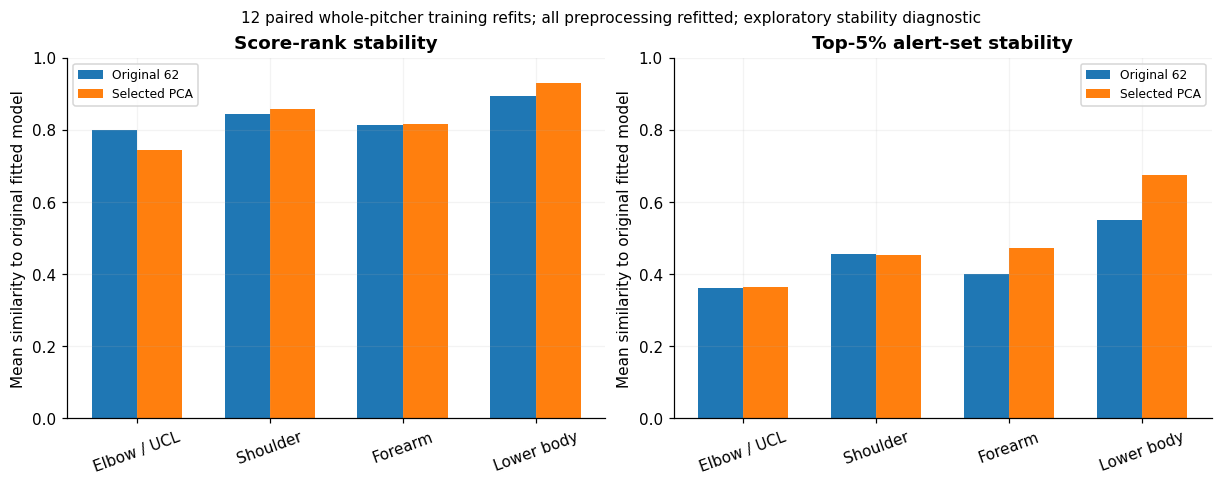

,category,variant,repeats,ap_mean,ap_sd,score_rank_correlation_mean,alert_jaccard_mean,mean_absolute_score_change
0,Elbow / UCL,Original 62,12,0.040444,0.003525,0.799344,0.360925,0.007869
1,Elbow / UCL,PCA 90%,12,0.036370,0.002761,0.743237,0.362961,0.005519
2,Forearm,Original 62,12,0.021694,0.005592,0.812296,0.398502,0.006152
3,Forearm,PCA 20,12,0.015865,0.002501,0.814654,0.472008,0.004009
4,Lower body,Original 62,12,0.045533,0.003847,0.893558,0.549465,0.012833
5,Lower body,PCA 90%,12,0.043664,0.001722,0.928358,0.675394,0.009949
6,Shoulder,Original 62,12,0.052529,0.003452,0.844541,0.454324,0.009575
7,Shoulder,PCA 90%,12,0.046017,0.002967,0.857763,0.452916,0.007659


,category,condition,variant,rows,events,prevalence,ap_delta,delta_low,delta_high,average_precision,roc_auc
0,Elbow / UCL,Starter,Original 62,6449,60,0.036440,0.000000,0.000000,0.000000,0.064163,0.608187
1,Elbow / UCL,Starter,PCA 90%,6449,60,0.036440,-0.017630,-0.054037,0.001458,0.046533,0.579510
2,Elbow / UCL,Reliever,Original 62,21216,60,0.022294,0.000000,0.000000,0.000000,0.036322,0.618810
3,Elbow / UCL,Reliever,PCA 90%,21216,60,0.022294,-0.003300,-0.012976,0.003482,0.033022,0.599415
4,Elbow / UCL,Unseen training pitcher,Original 62,12017,55,0.031039,0.000000,0.000000,0.000000,0.055397,0.626813
5,Elbow / UCL,Unseen training pitcher,PCA 90%,12017,55,0.031039,-0.011449,-0.033892,0.003036,0.043947,0.595056
6,Elbow / UCL,Seen training pitcher,Original 62,15648,55,0.021408,0.000000,0.000000,0.000000,0.033613,0.597580
7,Elbow / UCL,Seen training pitcher,PCA 90%,15648,55,0.021408,-0.002333,-0.018227,0.006699,0.031280,0.602974
8,Elbow / UCL,Exclude final six days,Original 62,27477,104,0.018925,0.000000,0.000000,0.000000,0.029277,0.601044
9,Elbow / UCL,Exclude final six days,PCA 90%,27477,104,0.018925,-0.002716,-0.014913,0.002334,0.026561,0.594423


,min,max
category,,
Elbow / UCL,-0.005970,-0.003551
Forearm,-0.009700,-0.005633
Hand / wrist,0.011171,0.026164
Lower body,-0.003647,-0.002243
Other arm,0.001978,0.003345
Shoulder,-0.008316,-0.005872
Trunk / neck,-0.001659,-0.000233


In [4]:
stability=run_stability(a,spec)
influence=event_concentration_audit()
plots.stability_figure();plt.show()
display(stability)
display(read_table('predictive_subgroups'))
display(influence[influence.removed_positive_pitcher.notna()].groupby('category').ap_delta.agg(['min','max']))

In [5]:
from src.injury_analysis.reduction_report import write_synthesis
report=write_synthesis()
display(Markdown(report))
s=read_table('selected_pca_comparison').query("partition=='test'")
conclusion(f"Validation-selected global PCA improves test AP by point estimate in {s.ap_delta_original.gt(0).sum()}/7 injury categories; paired intervals exclude zero on the positive side in {s.delta_low_original.gt(0).sum()}/7. Interpret this alongside event warning, the small-group concentration audit, training-refit stability and the profile/departure trajectories. PCA is an interpretable compression experiment, not proof of latent physiological mechanisms or a newly validated injury-warning system.")

# Dimensionality reduction: executed exploratory findings

## Design and scope

This extension reuses the 62-feature cohort, 30-day injury definitions, category-versus-IL-free risk sets, and original 1,225 matched pairs. Training ends in 2021, validation covers 2022–2023, and the previously examined test period is 2024–2025, with the existing 60-day embargo. There is no new independent confirmatory test. All central data and preceding analyses remain intact.

The three notebooks distinguish (1) redundancy in 60 continuous selected predictors, keeping the two binary context variables outside PCA; (2) eight strictly prior pitcher baseline means; and (3) the corresponding eight current pitcher-relative departures. Arm angle remains outside the long-history experiment because of structural availability. Predictive comparisons use the original 62 features; the extra baseline measurements support description only.

All medians, scales and PCA bases are fitted on training rows. Descriptive maps use one common label-free training cohort; predictive PCA is refitted separately inside each category's training cohort. PCA is linear, unwhitened and unsupervised. Components maximize feature variance, not injury discrimination. No label-colored embedding is treated as evidence of natural injury clusters.

## Main findings

- **Moderate redundancy, not a tiny latent space:** 31 of 60 continuous dimensions retain 90% of training variance. The first two retain only 19.6%.
- **Distinct temporal representations:** prior-profile PCs vary mainly between pitchers; departure PCs vary mainly within pitchers. In the held-out matched comparison, the displayed profile axes show no clear large case/control separation, while shoulder departure components contain both a sustained mixed-measurement offset and a late change.
- **Shoulder's late multivariate change:** departure PC2's excess final step is -0.438 training-PC SD (-0.831 to -0.112; 68 pairs). It combines velocity, release height, spin and extension and is not a physiological diagnosis.
- **No broad AP improvement:** validation-selected global PCA improves test AP by point estimate in 2/7 categories. Hand/wrist has a large test gain (+0.0235) but a validation change of -0.0007; the small-event and pitcher-influence audits remain important.
- **AP and practical event warning can disagree:** for shoulder, the selected PCA model warns 23.0% of events versus 17.4% for the original features at the same 5% budget. The paired event-recall difference is 5.6% (conditional interval 0.6% to 10.8%), despite lower shoulder AP. This is an exploratory metric-specific benefit, not confirmation of a superior warning system.

## 1. Redundancy and dimension

| block                    |   features |   training_rows |   training_pitchers |   first_two_fraction |   components_80 |   components_90 |   components_95 |   participation_rank |   pairs_abs_corr_90 |
|:-------------------------|-----------:|----------------:|--------------------:|---------------------:|----------------:|----------------:|----------------:|---------------------:|--------------------:|
| Current feature space    |     60.000 |      123833.000 |            1492.000 |                0.196 |          23.000 |          31.000 |          38.000 |               22.274 |               5.000 |
| Prior pitcher profile    |      8.000 |      123833.000 |            1492.000 |                0.370 |           6.000 |           7.000 |           8.000 |                7.041 |               0.000 |
| Within-pitcher departure |      8.000 |      123833.000 |            1492.000 |                0.329 |           6.000 |           7.000 |           8.000 |                7.556 |               0.000 |

The full continuous feature space needs 31/60 components for 90% of variance and 38/60 for 95%. The first two explain 19.6%. Correlated transformations permit compression, but a two-dimensional scatter omits most variation. The participation rank is a variance-concentration summary, not an estimate of biological dimensionality.

The baseline and departure blocks each retain broad structure rather than collapsing to one or two factors. `high_correlations.csv` records the actual redundant pairs. Binary fields and missingness flags are not rotated into measurement components.

## 2. What drives the axes?

The three largest absolute projection weights for each displayed component are:

| block                    |   component | feature                                |   weight |   feature_score_correlation |
|:-------------------------|------------:|:---------------------------------------|---------:|----------------------------:|
| Current feature space    |           1 | starts_prev_30d                        |    0.330 |                       0.934 |
| Current feature space    |           1 | starter_share_prev_5                   |    0.324 |                       0.917 |
| Current feature space    |           1 | total_pitches                          |    0.318 |                       0.901 |
| Current feature space    |           2 | acute_chronic_pitch_ratio              |    0.283 |                       0.547 |
| Current feature space    |           2 | velo_z                                 |   -0.273 |                      -0.528 |
| Current feature space    |           2 | fb_velo_change_vs_prev_5               |   -0.266 |                      -0.513 |
| Current feature space    |           3 | fastball_usage_pct_change_vs_prev_5    |    0.400 |                       0.759 |
| Current feature space    |           3 | fastball_usage_pct                     |    0.381 |                       0.723 |
| Current feature space    |           3 | vertical_movement_avg_change_vs_prev_5 |    0.353 |                       0.669 |
| Prior pitcher profile    |           1 | avg_fb_velo_baseline_mean              |    0.525 |                       0.687 |
| Prior pitcher profile    |           1 | release_z_sd_baseline_mean             |   -0.518 |                      -0.677 |
| Prior pitcher profile    |           1 | release_x_sd_baseline_mean             |   -0.372 |                      -0.487 |
| Prior pitcher profile    |           2 | release_z_avg_baseline_mean            |    0.617 |                       0.689 |
| Prior pitcher profile    |           2 | extension_avg_baseline_mean            |   -0.439 |                      -0.490 |
| Prior pitcher profile    |           2 | release_x_avg_baseline_mean            |    0.423 |                       0.472 |
| Prior pitcher profile    |           3 | release_x_sd_baseline_mean             |    0.603 |                       0.661 |
| Prior pitcher profile    |           3 | avg_fb_velo_baseline_mean              |    0.378 |                       0.415 |
| Prior pitcher profile    |           3 | release_z_sd_baseline_mean             |    0.365 |                       0.400 |
| Within-pitcher departure |           1 | release_z_sd_z                         |    0.694 |                       0.820 |
| Within-pitcher departure |           1 | release_x_sd_z                         |    0.681 |                       0.805 |
| Within-pitcher departure |           1 | zone_pct_z                             |   -0.139 |                      -0.164 |
| Within-pitcher departure |           2 | velo_z                                 |    0.630 |                       0.700 |
| Within-pitcher departure |           2 | release_z_z                            |   -0.498 |                      -0.554 |
| Within-pitcher departure |           2 | spin_z                                 |    0.406 |                       0.451 |
| Within-pitcher departure |           3 | spin_z                                 |    0.569 |                       0.612 |
| Within-pitcher departure |           3 | extension_z                            |   -0.517 |                      -0.556 |
| Within-pitcher departure |           3 | release_z_z                            |    0.410 |                       0.442 |

Weights refer to standardized original variables; correlations describe feature/score association. Component signs are arbitrary. Names such as profile or departure describe the input construction, not validated physiological mechanisms. Current-feature PC1's correlation with starter status is 0.886. Its large workload/role contribution can dominate an unsupervised map even when the research question concerns mechanics.

Training between-pitcher variance fractions are:

| block                    |   component |   between_pitcher_fraction |   corr_starter |   corr_left_handed |
|:-------------------------|------------:|---------------------------:|---------------:|-------------------:|
| Current feature space    |           1 |                      0.816 |          0.886 |              0.009 |
| Current feature space    |           2 |                      0.099 |          0.099 |              0.080 |
| Current feature space    |           3 |                      0.143 |         -0.009 |             -0.079 |
| Prior pitcher profile    |           1 |                      0.911 |         -0.119 |             -0.410 |
| Prior pitcher profile    |           2 |                      0.909 |          0.095 |              0.409 |
| Prior pitcher profile    |           3 |                      0.876 |         -0.019 |             -0.182 |
| Within-pitcher departure |           1 |                      0.019 |          0.025 |              0.006 |
| Within-pitcher departure |           2 |                      0.033 |         -0.032 |              0.007 |
| Within-pitcher departure |           3 |                      0.033 |         -0.018 |             -0.015 |

For the first three prior-profile PCs, 87.6%–91.1% of score variance is between pitchers, versus 1.9%–3.3% for departure PCs. This supports keeping the two representations separate. It is also partly expected from their construction: a rolling prior mean is smooth, whereas a z-score measures departures. These fractions are descriptive sums of squares, not random-effects ICC estimates or proof of susceptibility.

## 3. Injury-group separation and approach-to-event changes

Primary latent trajectories use only original matched pairs whose complete observed windows and injury anchors lie in 2022–2025, outside PCA training. Each scored trajectory point requires all eight measured inputs for its block. Balanced curves keep the same case/control pairs across all five outings or four calendar bins. All-year results and all-available-pair curves are separate sensitivity outputs. Bands resample whole case pitchers and are simultaneous across time within a component/category, not across every comparison.

Selected paired contrasts (training-PC SD units) are:

| feature       | category    | metric                     |   mean |    low |   high |   events |
|:--------------|:------------|:---------------------------|-------:|-------:|-------:|---------:|
| profile_PC1   | Elbow / UCL | average_separation         |  0.105 | -0.166 |  0.348 |       71 |
| profile_PC1   | Elbow / UCL | final_step_vs_previous_two |  0.007 | -0.010 |  0.031 |       71 |
| profile_PC1   | Forearm     | average_separation         | -0.127 | -0.458 |  0.261 |       29 |
| profile_PC1   | Forearm     | final_step_vs_previous_two | -0.001 | -0.016 |  0.015 |       29 |
| profile_PC1   | Lower body  | average_separation         | -0.101 | -0.386 |  0.252 |       75 |
| profile_PC1   | Lower body  | final_step_vs_previous_two | -0.006 | -0.022 |  0.008 |       75 |
| profile_PC1   | Shoulder    | average_separation         |  0.051 | -0.227 |  0.325 |       78 |
| profile_PC1   | Shoulder    | final_step_vs_previous_two |  0.004 | -0.006 |  0.014 |       78 |
| departure_PC2 | Elbow / UCL | average_separation         | -0.025 | -0.272 |  0.260 |       62 |
| departure_PC2 | Elbow / UCL | final_step_vs_previous_two | -0.201 | -0.621 |  0.224 |       62 |
| departure_PC2 | Forearm     | average_separation         | -0.022 | -0.320 |  0.338 |       29 |
| departure_PC2 | Forearm     | final_step_vs_previous_two | -0.150 | -0.620 |  0.361 |       29 |
| departure_PC2 | Lower body  | average_separation         | -0.191 | -0.447 |  0.027 |       69 |
| departure_PC2 | Lower body  | final_step_vs_previous_two |  0.207 | -0.092 |  0.488 |       69 |
| departure_PC2 | Shoulder    | average_separation         | -0.180 | -0.384 |  0.034 |       68 |
| departure_PC2 | Shoulder    | final_step_vs_previous_two | -0.438 | -0.831 | -0.112 |       68 |
| departure_PC3 | Elbow / UCL | average_separation         |  0.014 | -0.190 |  0.264 |       62 |
| departure_PC3 | Elbow / UCL | final_step_vs_previous_two | -0.139 | -0.472 |  0.198 |       62 |
| departure_PC3 | Forearm     | average_separation         | -0.125 | -0.364 |  0.170 |       29 |
| departure_PC3 | Forearm     | final_step_vs_previous_two |  0.106 | -0.404 |  0.606 |       29 |
| departure_PC3 | Lower body  | average_separation         |  0.165 | -0.118 |  0.429 |       69 |
| departure_PC3 | Lower body  | final_step_vs_previous_two |  0.219 | -0.179 |  0.553 |       69 |
| departure_PC3 | Shoulder    | average_separation         | -0.445 | -0.660 | -0.230 |       68 |
| departure_PC3 | Shoulder    | final_step_vs_previous_two | -0.200 | -0.547 |  0.145 |       68 |

Read `average_separation` as a persistent case/control offset; read `final_step_vs_previous_two` as the excess final-outing change after subtracting the control's own change. The first two axes show broad event overlap. Absence of separation there does not establish absence of signal in omitted components. Departure PC2 includes velocity, release height, spin and extension; a negative change is a weighted combination, not a pure velocity decline or injury-onset estimate.

The departure view also contains a sustained shoulder offset in PC3: -0.445 training-PC SD averaged across the final five outings (95% interval -0.660 to -0.230; 68 pairs). This component loads positively on spin, release height and velocity and negatively on extension. It shows why a within-pitcher departure need not be an abrupt change: departures can persist across several outings. The smaller balanced calendar cohort and multiple-comparison uncertainty prevent assigning a precise onset or universal warning time to this offset.

All six displayed axes are exported, including uncertain/null comparisons. Same-throwing-hand, strict-QA, role and final-week-exclusion checks are in `latent_sensitivity.csv`. A visual mean trajectory cannot be interpreted as a reliable individual warning threshold. Recorded dates remain injury/IL proxies; current-outing measurements become available after the outing.

## 4. Predictive comparison

The logistic model, C=1 penalty, labels and rows remain the same. Numerical convergence is tightened consistently for every new fit. Full-rank unwhitened PCA is an orthogonal-rotation control and should preserve the same linear prediction problem; the largest observed AP discrepancy is 0.00000020. `full_rotation_sanity.csv` also compares the tighter original-feature refit with the preserved earlier default-tolerance results. This is a numerical refinement, not a change to injury labels or historical results.

Global PCA dimensions 5, 10, 20 and a training-only 90%-variance cutoff are predeclared. A single global-PCA specification per category is selected by validation AP only. Workload/history plus compressed Statcast is a separate fixed comparison. The table below reports test results for the validation-selected global specification:

| category     | variant   |   design_dimensions |   average_precision |   pr_lift |   ap_delta_original |   delta_low_original |   delta_high_original |
|:-------------|:----------|--------------------:|--------------------:|----------:|--------------------:|---------------------:|----------------------:|
| Elbow / UCL  | PCA 90%   |                  77 |              0.0374 |    1.4620 |             -0.0052 |              -0.0169 |                0.0016 |
| Shoulder     | PCA 90%   |                  77 |              0.0484 |    1.5853 |             -0.0075 |              -0.0168 |               -0.0010 |
| Forearm      | PCA 20    |                  67 |              0.0143 |    1.3987 |             -0.0085 |              -0.0233 |                0.0018 |
| Other arm    | PCA 10    |                  57 |              0.0129 |    1.3526 |              0.0028 |              -0.0017 |                0.0076 |
| Trunk / neck | PCA 90%   |                  77 |              0.0262 |    1.5914 |             -0.0011 |              -0.0068 |                0.0028 |
| Lower body   | PCA 90%   |                  77 |              0.0450 |    1.9515 |             -0.0032 |              -0.0098 |                0.0010 |
| Hand / wrist | PCA 90%   |                  77 |              0.0327 |    5.1653 |              0.0235 |               0.0011 |                0.0758 |

Selected global PCA has higher test AP by point estimate in 2/7 categories; its paired 95% interval excludes zero on the positive side in 1/7. These are conditional fitted-model intervals, without validation-selection or multiple-comparison adjustment. Compare the full validation/test table rather than calling the largest test result a winner.

“PCA 5” is not a five-predictor model: the two binary fields and all training-observed missingness flags remain outside PCA. Actual design sizes, including these columns, are:

| variant                 |   source_features |   retained_components |   missingness_indicators |   unrotated_columns |   design_dimensions |
|:------------------------|------------------:|----------------------:|-------------------------:|--------------------:|--------------------:|
| Full-rank PCA control   |                62 |                    60 |                       45 |                  47 |                 107 |
| Original 62             |                62 |                     0 |                       45 |                 107 |                 107 |
| PCA 10                  |                62 |                    10 |                       45 |                  47 |                  57 |
| PCA 20                  |                62 |                    20 |                       45 |                  47 |                  67 |
| PCA 5                   |                62 |                     5 |                       45 |                  47 |                  52 |
| PCA 90%                 |                62 |                    30 |                       45 |                  47 |                  77 |
| Role/hand + missingness |                62 |                     0 |                       45 |                  47 |                  47 |
| WH + Statcast PCA 10    |                62 |                    10 |                       45 |                  67 |                  77 |
| WH + Statcast PCA 90%   |                62 |                    23 |                       45 |                  67 |                  90 |
| Workload + history      |                22 |                     0 |                       13 |                  35 |                  35 |

The role/hand-plus-missingness diagnostic tests whether metadata and feature availability carry information without continuous feature values:

| category     | variant                 |   average_precision |   pr_lift |
|:-------------|:------------------------|--------------------:|----------:|
| Elbow / UCL  | Original 62             |              0.0426 |    1.6657 |
| Elbow / UCL  | Workload + history      |              0.0441 |    1.7249 |
| Elbow / UCL  | Role/hand + missingness |              0.0312 |    1.2190 |
| Shoulder     | Original 62             |              0.0559 |    1.8314 |
| Shoulder     | Workload + history      |              0.0497 |    1.6272 |
| Shoulder     | Role/hand + missingness |              0.0341 |    1.1154 |
| Forearm      | Original 62             |              0.0228 |    2.2269 |
| Forearm      | Workload + history      |              0.0121 |    1.1840 |
| Forearm      | Role/hand + missingness |              0.0168 |    1.6361 |
| Other arm    | Original 62             |              0.0101 |    1.0612 |
| Other arm    | Workload + history      |              0.0154 |    1.6137 |
| Other arm    | Role/hand + missingness |              0.0108 |    1.1330 |
| Trunk / neck | Original 62             |              0.0273 |    1.6585 |
| Trunk / neck | Workload + history      |              0.0292 |    1.7748 |
| Trunk / neck | Role/hand + missingness |              0.0178 |    1.0802 |
| Lower body   | Original 62             |              0.0482 |    2.0910 |
| Lower body   | Workload + history      |              0.0478 |    2.0744 |
| Lower body   | Role/hand + missingness |              0.0272 |    1.1804 |
| Hand / wrist | Original 62             |              0.0092 |    1.4571 |
| Hand / wrist | Workload + history      |              0.0136 |    2.1384 |
| Hand / wrist | Role/hand + missingness |              0.0089 |    1.4021 |

This diagnostic is not pure missingness: it explicitly retains role and throwing hand. Missingness also reflects historical availability and prior observation support. It must not be assigned a physiological interpretation.

## 5. Generalization, stability and practical warning

| category    | variant     |   repeats |   ap_mean |   ap_sd |   score_rank_correlation_mean |   alert_jaccard_mean |   mean_absolute_score_change |
|:------------|:------------|----------:|----------:|--------:|------------------------------:|---------------------:|-----------------------------:|
| Elbow / UCL | Original 62 |        12 |    0.0404 |  0.0035 |                        0.7993 |               0.3609 |                       0.0079 |
| Elbow / UCL | PCA 90%     |        12 |    0.0364 |  0.0028 |                        0.7432 |               0.3630 |                       0.0055 |
| Forearm     | Original 62 |        12 |    0.0217 |  0.0056 |                        0.8123 |               0.3985 |                       0.0062 |
| Forearm     | PCA 20      |        12 |    0.0159 |  0.0025 |                        0.8147 |               0.4720 |                       0.0040 |
| Lower body  | Original 62 |        12 |    0.0455 |  0.0038 |                        0.8936 |               0.5495 |                       0.0128 |
| Lower body  | PCA 90%     |        12 |    0.0437 |  0.0017 |                        0.9284 |               0.6754 |                       0.0099 |
| Shoulder    | Original 62 |        12 |    0.0525 |  0.0035 |                        0.8445 |               0.4543 |                       0.0096 |
| Shoulder    | PCA 90%     |        12 |    0.0460 |  0.0030 |                        0.8578 |               0.4529 |                       0.0077 |

Twelve paired whole-pitcher training bootstrap refits relearn imputation, scaling, PCA and logistic coefficients. The originally selected dimension specification is fixed; a 90% variance rule still learns its retained count inside each refit. Rank correlation and alert-set Jaccard measure similarity to the original fit; larger values indicate greater stability. AP SD across these refits measures training perturbation sensitivity on a fixed test cohort, not a confidence interval for generalization. Original-feature coefficient stability is separately exported to avoid interpreting arbitrary PCA sign changes as instability.

At a retrospective 5% alert budget:

| category     | variant     |   qualifying_events |   injury_event_recall |   random_expected_event_recall |   median_warning_lead_days |
|:-------------|:------------|--------------------:|----------------------:|-------------------------------:|---------------------------:|
| Elbow / UCL  | Original 62 |                 145 |                 0.179 |                          0.157 |                     17.500 |
| Elbow / UCL  | PCA 90%     |                 145 |                 0.179 |                          0.157 |                     24.500 |
| Shoulder     | Original 62 |                 161 |                 0.174 |                          0.170 |                     16.500 |
| Shoulder     | PCA 90%     |                 161 |                 0.230 |                          0.170 |                     21.000 |
| Forearm      | Original 62 |                  46 |                 0.174 |                          0.196 |                     26.500 |
| Forearm      | PCA 20      |                  46 |                 0.174 |                          0.196 |                     21.000 |
| Other arm    | Original 62 |                  45 |                 0.089 |                          0.184 |                     27.500 |
| Other arm    | PCA 10      |                  45 |                 0.156 |                          0.184 |                     17.000 |
| Trunk / neck | Original 62 |                  85 |                 0.176 |                          0.174 |                     23.000 |
| Trunk / neck | PCA 90%     |                  85 |                 0.176 |                          0.174 |                     26.000 |
| Lower body   | Original 62 |                 125 |                 0.192 |                          0.162 |                     24.500 |
| Lower body   | PCA 90%     |                 125 |                 0.200 |                          0.162 |                     26.000 |
| Hand / wrist | Original 62 |                  33 |                 0.212 |                          0.174 |                     12.000 |
| Hand / wrist | PCA 90%     |                  33 |                 0.273 |                          0.174 |                     24.000 |

Events need a warning 7–30 days before the recorded reference; all eligible events remain in the denominator, including events lacking a warning opportunity. Random expectations account for repeated opportunities. Event-difference intervals, false/non-actionable alert burden, warning-lead distributions and validation-fixed score thresholds are saved separately. Stability or row AP improvement need not translate into better event warning.

Frozen subgroup checks cover starters, relievers, seen/unseen training pitchers and exclusion of final-six-day positives. `positive_pitcher_influence.csv` removes each positive pitcher's rows in turn without refitting or selecting models. The range of the selected model's AP difference across those exclusions is:

| category     |     min |     max |
|:-------------|--------:|--------:|
| Elbow / UCL  | -0.0060 | -0.0036 |
| Forearm      | -0.0097 | -0.0056 |
| Hand / wrist |  0.0112 |  0.0262 |
| Lower body   | -0.0036 | -0.0022 |
| Other arm    |  0.0020 |  0.0033 |
| Shoulder     | -0.0083 | -0.0059 |
| Trunk / neck | -0.0017 | -0.0002 |

This identifies concentration in a few injured pitchers; it is not another model-selection procedure. Small categories remain uncertain even if one test-period point estimate is large.

## 6. Limits and implications

PCA supplies interpretable combinations and a controlled compression experiment; it does not turn components into physiological constructs. The variance objective can discard low-variance injury information. Prior profiles and departures have different temporal behavior, but persistent profiles are not automatically causal susceptibility factors, and late departures may reflect existing symptoms.

PCA bases are additionally checked under capped pitcher contributions, complete-measurement training and early/recent training eras. `subspace_sensitivity.csv` reports sign-invariant subspace overlap. Shared scaling isolates basis changes; this sensitivity does not refit a deployable model. Near-equal eigenvalues can make individual axes less stable than their combined subspace.

No nonlinear embedding is added merely to create apparent clusters. Given weak low-dimensional variance concentration, repeated observations, and the need for auditable held-out transformation and loadings, linear PCA answers the present questions more directly. This does not rule out nonlinear structure.

Remaining limits include selected active-pitcher controls; revised/vague injury descriptions; unverified contemporaneous reporting; missing historical measurements; partial 2026 observation (all-year description only); cross-pair dependence when a person appears elsewhere as a control; and many exploratory comparisons. A new independent evaluation period and adjudicated event timing remain necessary before a clinical or operational warning claim.

## Artifacts

Three executed notebooks: `notebooks/injury_dimensionality_reduction/`. Tables and publication-size PNG/PDF figures: `reports/injury_dimensionality_reduction/`. Fitted transforms, narrow scores, matched latent cells and predictions: `data/injury/analysis/dimensionality_reduction/`. Source DuckDB and previous analysis results are preserved.

Method references: [scikit-learn 1.6 PCA](https://scikit-learn.org/1.6/modules/generated/sklearn.decomposition.PCA.html) and [training-only preprocessing guidance](https://scikit-learn.org/1.6/common_pitfalls.html).


**Computed conclusion.** Validation-selected global PCA improves test AP by point estimate in 2/7 injury categories; paired intervals exclude zero on the positive side in 1/7. Interpret this alongside event warning, the small-group concentration audit, training-refit stability and the profile/departure trajectories. PCA is an interpretable compression experiment, not proof of latent physiological mechanisms or a newly validated injury-warning system.